# Water well experimentation
Install the package with `pip install -e ".[dev]"` first. All modeling logic lives in `water_wells`. Run from the repository root or its notebooks directory.

In [1]:
from pathlib import Path
from water_wells import (DataConfig, DataLoader, TrainingConfig,
                         TrainingPipeline, ModelEvaluator)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
loader = DataLoader(DataConfig(data_dir=ROOT))
X, y = loader.load_training()
X.shape, y.value_counts()

((59400, 40),
 status_group
 functional                 32259
 non functional             22824
 functional needs repair     4317
 Name: count, dtype: int64)

In [15]:
X.columns

Index(['id', 'amount_tsh', 'date_recorded', 'funder', 'gps_height',
       'installer', 'longitude', 'latitude', 'wpt_name', 'num_private',
       'basin', 'subvillage', 'region', 'region_code', 'district_code', 'lga',
       'ward', 'population', 'public_meeting', 'recorded_by',
       'scheme_management', 'scheme_name', 'permit', 'construction_year',
       'extraction_type', 'extraction_type_group', 'extraction_type_class',
       'management', 'management_group', 'payment', 'payment_type',
       'water_quality', 'quality_group', 'quantity', 'quantity_group',
       'source', 'source_type', 'source_class', 'waterpoint_type',
       'waterpoint_type_group'],
      dtype='str')

## Split raw data, then fit
Only training rows fit the geographic reference, imputers, encoders, and model. The original notebook used 500 estimators and a 25% validation fraction.

In [2]:
config = TrainingConfig(model_path=ROOT / "models/water_well_model.joblib")
pipeline = TrainingPipeline(config)
X_train, X_valid, y_train, y_valid = pipeline.split(X, y)
pipeline.fit(X_train, y_train)

,config,TrainingConfi...'n_jobs': -1})
,population_raster,None
,cache_dir,'data/processed/population'
,data_mode,'auto'
Name,Type,Value
classes_,"ndarray[object](3,)","['functional','functional needs repair','non functional']"
pipeline_,Pipeline,Pipeline(step...ple': 0.8}))])


In [17]:
evaluator = ModelEvaluator()
predictions = pipeline.predict(X_valid)
evaluator.metrics(y_valid, predictions)

{'accuracy': 0.7874747474747474,
 'precision': 0.7896946457034099,
 'recall': 0.7874747474747474,
 'f1': 0.7729856010923525}

In [4]:
print(evaluator.classification_report(y_valid, predictions))
evaluator.confusion_matrix(y_valid, predictions)

                         precision    recall  f1-score   support

             functional       0.76      0.92      0.83      8065
functional needs repair       0.68      0.22      0.33      1079
         non functional       0.85      0.70      0.77      5706

               accuracy                           0.79     14850
              macro avg       0.76      0.62      0.65     14850
           weighted avg       0.79      0.79      0.77     14850



,functional,functional needs repair,non functional
functional,7448,69,548
functional needs repair,695,237,147
non functional,1654,43,4009


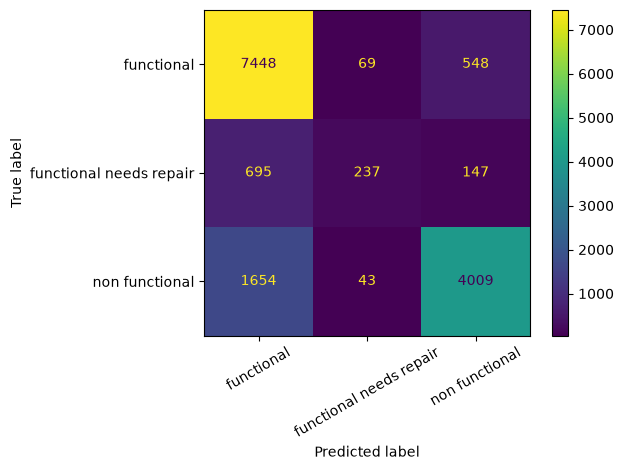

In [5]:
evaluator.plot_confusion_matrix(y_valid, predictions);



In [6]:
evaluator.plot_feature_importance(pipeline, top_n=500);

In [7]:
pipeline.predict_proba(X_valid.head())

,functional,functional needs repair,non functional
44614,0.137582,0.013917,0.848502
42868,0.494583,0.247008,0.258408
24507,0.809495,0.072130,0.118374
35407,0.322442,0.086499,0.591059
48257,0.805775,0.035138,0.159087


In [8]:
pipeline.predict_wells(X_valid.head())

,id,latitude,longitude,predicted_status,probability_functional,probability_needs_repair,probability_non_functional
44614,49391,-1.242508,33.911895,non functional,0.137582,0.013917,0.848502
42868,12638,-1.480412,31.740816,functional,0.494583,0.247008,0.258408
24507,41709,-3.853344,35.483507,functional,0.809495,0.072130,0.118374
35407,7072,-4.464789,38.077040,non functional,0.322442,0.086499,0.591059
48257,15294,-4.424756,33.435959,functional,0.805775,0.035138,0.159087


## Save and reload
Load serialized artifacts only from trusted sources. This saves the training-split model; fit a fresh pipeline on all labeled rows after finalizing your experiment to make a final inference artifact.

In [9]:
pipeline.save()
restored = TrainingPipeline.load(config.model_path)
assert (restored.predict(X_valid.head()) == pipeline.predict(X_valid.head())).all()

## New unlabeled wells
Use the original feature schema. `predict_wells` preserves IDs, row order, index, and raw coordinates.

In [10]:
# new_wells = loader.load_test("data/raw/test_values.csv")
# results = restored.predict_wells(new_wells)
# results.to_csv(ROOT / "data/processed/predictions.csv", index=False)

## Cross-validation
`TrainingPipeline` is sklearn compatible. Every fold fits its own spatial reference and encoder; use raw features and readable target labels.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_val_score(TrainingPipeline(config), X, y, cv=cv, scoring="accuracy")

In [12]:
scores

array([0.79131313, 0.78545455, 0.78732323])